# SmartWatches Analysis Using Web Scraping & EDA

In [1]:
import requests
import re
import time
import random
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup

In [2]:
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/137.0.0.0 Safari/537.36",
    "Accept-Language": "en-IN,en;q=0.9",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
    "Referer": "https://www.google.com/"
}
session = requests.Session()      
session.headers.update(headers)

In [3]:
url = 'https://www.amazon.in/s?k=smart+watches+under+10000+for+men&crid=1Z5W8ITUY63B4&sprefix=smart+watches%2Caps%2C311&ref=nb_sb_ss_mvt-t11-ranker_3_13'
response = session.get(url, timeout=30)

In [4]:
response.status_code

200

In [5]:
html_data = response.text
soup = BeautifulSoup(html_data, "html.parser")

In [6]:
cards = soup.find_all("div", {"data-component-type": "s-search-result"})
cards

[<div class="sg-col-4-of-4 sg-col-20-of-24 s-result-item s-asin sg-col-16-of-20 AdHolder sg-col sg-col-12-of-12 s-widget-spacing-small sg-col-8-of-8 sg-col-12-of-16" data-asin="B0F7XWCCY3" data-component-type="s-search-result" data-index="4" data-uuid="5fc29730-cc80-4ec4-a572-03563d454a1b" id="5fc29730-cc80-4ec4-a572-03563d454a1b" role="listitem"><div class="sg-col-inner"><div cel_widget_id="MAIN-SEARCH_RESULTS-4" class="s-widget-container s-spacing-small s-widget-container-height-small celwidget slot=MAIN template=SEARCH_RESULTS widgetId=search-results_1" data-csa-c-asin-instance-id="307ce238-03a3-49a3-aea6-b4dfcd13fc46" data-csa-c-content-id="search-results_1" data-csa-c-cs-type="Loom" data-csa-c-item-id="amzn1.asin.1.B0F7XWCCY3" data-csa-c-pos="1" data-csa-c-type="item" data-csa-op-log-render="">
 <div class="rush-component" data-component-props='{"percentageShownToFire":"50","batchable":true,"requiredElementSelector":".s-image:visible","url":"https://unagi-eu.amazon.com/1/events/co

In [7]:
Product_name = []

for i in cards:
    title = i.select_one("h2")
    if title:
        name = title.get("aria-label") or title.get_text(" ", strip=True)
        if name:
            name = name.replace("Sponsored Ad - ", "")
            Product_name.append(name)

In [8]:
Product_name = [
    re.sub(r'(?i)^Sponsored Ad\s*-\s*', '', name).strip()
    for name in Product_name
]

Product_name

['Noise Endeavour Pro (Smartchoice) Outdoor Rugged Military Smart Watch, Dual-Band GPS, 164ft Water Resistance, 28 Days Battery on Standby, AI Companion, for iOS & Android (Carbon Black)',
 'Amazfit Bip Max 50mm Smartwatch, 2.07" AMOLED Display, 20 Days of Battery, GPS, 4GB Storage, Offline Maps, Fitness Tracker, Hybrid Training, 150+ Sports, HYROX Mode, 5 ATM for Android & iPhone, Blue',
 'boAt Wave Call 3 Smartwatch 1.83” HD Display with Animated Watch Faces; BT Calling, Functional Crown, Multiple Sports Modes, IP68, HR, SpO2 Monitor, Smart Watches for Men & Women (Bold Black)',
 'Fire-Boltt Ninja Call Pro Plus Bluetooth Calling Smart Watch, 1.83″ HD Display, AI Voice Assistant, 120+ Sports Modes, IP67 Waterproof, SpO2 & Heart Rate Monitor Smartwatch for Men & Women - Black',
 'Amazfit Active 2 Square Smartchoice, 2000 Nits Bright AMOLED Display, Built in GPS, 10Day Battery, Android & iPhone, Accurate Readings, BT Call, Sleep Monitor, 5ATM Water Resistant, Black Leather',
 'Amazfit A

In [9]:
Brand = []

for name in Product_name:
    name = re.sub(r'(?i)^Sponsored Ad\s*-\s*', '', name).strip()

    brand = name.split()[0] if name else None
    Brand.append(brand)

print(Brand)
print("Total brands:", len(Brand))

['Noise', 'Amazfit', 'boAt', 'Fire-Boltt', 'Amazfit', 'Amazfit', 'T800', 'Noise', 'Titan', 'Noise', 'Fire‑Boltt', 'boAt', 'Noise', 'Titan', 'Fastrack', 'Fire-Boltt', 'Fastrack', 'Bouncefit', 'Fire-Boltt', 'Titan', 'Fire-Boltt', 'CrossBeats']
Total brands: 22


In [10]:
def get_text(card, selector):
    tag = card.select_one(selector)
    return tag.get_text(strip=True) if tag else None

def get_title(card):
    h2s = [h.get("aria-label") or h.get_text(" ", strip=True) for h in card.find_all("h2")]
    return max(h2s, key=len) if h2s else None

def get_display(title):
    m = re.search(r'(\d{1,2}\.\d+)\s*(inch|inches|cm|"|”|″)', str(title), re.I)
    if m:
        return m.group(1) + (" cm" if m.group(2).lower() == "cm" else " inch")
    return None

def num(x):
    return int(re.search(r"[\d,]+", x).group().replace(",", ""))

def scrape_card(card):
    title = get_title(card)
    price = get_text(card, "span.a-price:not(.a-text-price) span.a-offscreen")
    mrp = get_text(card, "span.a-price.a-text-price span.a-offscreen")
    rating = get_text(card, "span.a-icon-alt")
    reviews = get_text(card, "span.s-underline-text")
    # FIX: sometimes the "MRP" selector picks up junk such as "₹0.07" - keep MRP only if it is a real, higher price
    try:
        if price and mrp and num(mrp) <= num(price):
            mrp = None
    except (AttributeError, ValueError):
        mrp = None
    m = re.search(r"(\d+)%\s*off", card.get_text(" "))
    if m:
        discount = m.group(1) + "% off"
    elif price and mrp and num(mrp) > num(price):
        discount = str(round((num(mrp) - num(price)) * 100 / num(mrp))) + "% off"
    else:
        discount = "0% off"
    return title, get_display(title), price, mrp, discount, rating, reviews

In [11]:
Product_name = []
Brand = []
Display = []
Price = []
Original_Price = []
Discount = []
Rating = []
Reviews = []

for card in cards:
    if not card.get("data-asin"):      
        continue
    n, d, p, o, dis, r, rev = scrape_card(card)
    Product_name.append(n)
    Display.append(d)
    Price.append(p)
    Original_Price.append(o)
    Discount.append(dis)
    Rating.append(r)
    Reviews.append(rev)
for name in Product_name:
    name = re.sub(r'(?i)^Sponsored Ad\s*-\s*', '', name).strip()

    brand = name.split()[0] if name else None
    Brand.append(brand)

In [12]:
print(len(Product_name))
print(len(Brand))
print(len(Display))
print(len(Price))
print(len(Original_Price))
print(len(Discount))
print(len(Rating))
print(len(Reviews))

22
22
22
22
22
22
22
22


In [13]:
min_len = min(len(Product_name),
len(Brand),
len(Display),
len(Price),
len(Original_Price),
len(Discount),
len(Rating),
len(Reviews))

In [14]:
min_len

22

### Scraping multiple pages pages (several search words, up to 7 pages each)

In [15]:
keywords = [
    "smart watches",
    "smart watch for men",
    "smart watch for women",
    "bluetooth calling smart watch",
    "fitness smart watch",
    "amoled smart watch",
    "gps smart watch",
    "high battery life smart watch",
    "smart watch under 5000",
    "smart watch under 2000",
    "smart watch with calling"
]

user_agents = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/131.0.0.0 Safari/537.36",
    "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 Chrome/130.0.0.0 Safari/537.36",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 Version/17.0 Safari/605.1.15"
]

def get_brand(name):
   
    name = re.sub(r"[\u2010\u2011\u2012\u2013\u2014]", "-", name)
    return name.split()[0] if name else None

def fetch_page(url, params, retries=3):
   
    for attempt in range(1, retries + 1):
        try:
            session.headers["User-Agent"] = random.choice(user_agents)
            resp = session.get(url, params=params, timeout=(10, 30))
            if resp.status_code == 200 and "captcha" not in resp.text.lower():
                return resp
            print(f"   blocked/status {resp.status_code} (attempt {attempt}/{retries})")
        except requests.exceptions.RequestException as e:
            print(f"   request error: {type(e).__name__} (attempt {attempt}/{retries})")
        time.sleep(random.uniform(10, 20) * attempt)
    return None

Brand = []
Product_name = []
Display = []
Price = []
Original_Price = []
Discount = []
Rating = []
Reviews = []
seen = set()

for kw in keywords:
    for page in range(1, 8):
        response = fetch_page("https://www.amazon.in/s", {"k": kw, "page": page})
        if response is None:
            print(f"{kw} | page {page} | failed - moving to next keyword")
            break
        print(f"{kw} | page {page} | status code", response.status_code)

        soup = BeautifulSoup(response.text, "html.parser")
        cards = soup.find_all("div", {"data-component-type": "s-search-result"})

        if len(cards) == 0:
            break

        for card in cards:
            asin = card.get("data-asin")

            if not asin or asin in seen:
                continue

            seen.add(asin)
            n, d, p, o, dis, r, rev = scrape_card(card)
            if not n:
                continue

            
            n = re.sub(r"(?i)^Sponsored Ad\s*-\s*", "", n).strip()

            Product_name.append(n)
            Brand.append(get_brand(n))
            Display.append(d)
            Price.append(p)
            Original_Price.append(o)
            Discount.append(dis)
            Rating.append(r)
            Reviews.append(rev)

        print(f"   total unique products so far: {len(Product_name)}")
        time.sleep(random.uniform(2, 4))

   request error: ConnectionError (attempt 1/3)
   request error: ConnectionError (attempt 2/3)
smart watches | page 1 | status code 200
   total unique products so far: 20
smart watches | page 2 | status code 200
   total unique products so far: 42
smart watches | page 3 | status code 200
   total unique products so far: 60
smart watches | page 4 | status code 200
   total unique products so far: 77
smart watches | page 5 | status code 200
   total unique products so far: 92
smart watches | page 6 | status code 200
   total unique products so far: 108
smart watches | page 7 | status code 200
   total unique products so far: 127
smart watch for men | page 1 | status code 200
   total unique products so far: 133
smart watch for men | page 2 | status code 200
   total unique products so far: 140
smart watch for men | page 3 | status code 200
   total unique products so far: 149
smart watch for men | page 4 | status code 200
   total unique products so far: 159
smart watch for men | page 

In [16]:
print(len(Product_name))
print(len(Brand))
print(len(Display))
print(len(Price))
print(len(Original_Price))
print(len(Discount))
print(len(Rating))
print(len(Reviews))

536
536
536
536
536
536
536
536


In [17]:
min_len = min(len(Product_name),
len(Brand),
len(Display),
len(Price),
len(Original_Price),
len(Discount),
len(Rating),
len(Reviews))

In [18]:
min_len

536

In [19]:
df = pd.DataFrame({
    "Product_name": Product_name[:min_len],
    "Brand": Brand[:min_len],
    "Display": Display[:min_len],
    "Price": Price[:min_len],
    "Original_Price": Original_Price[:min_len],
    "Discount": Discount[:min_len],
    "Rating": Rating[:min_len],
    "Reviews": Reviews[:min_len]
})

In [20]:
df

,Product_name,Brand,Display,Price,Original_Price,Discount,Rating,Reviews
0,Fire-Boltt Ninja Call Pro Bluetooth Calling Sm...,Fire-Boltt,1.69 inch,"₹1,099","₹17,999",94% off,3.9 out of 5 stars,(1.3L)
1,"Fastrack Limitless FS2 Pro 1.96"" AMOLED Smart ...",Fastrack,1.96 inch,"₹2,099","₹7,995",74% off,4.0 out of 5 stars,(1.9K)
2,boAt Wave Call 3 Smartwatch 1.83” HD Display w...,boAt,1.83 inch,"₹1,099","₹6,999",84% off,4.1 out of 5 stars,(27K)
3,"1.83"" AMOLED Bluetooth Calling Smartwatch with...","1.83""",1.83 inch,₹499,"₹5,999",92% off,2.4 out of 5 stars,(17)
4,"boAt Chrome Endeavour, Premium Metal Body, 1.9...",boAt,1.96 inch,"₹3,999","₹10,499",62% off,4.0 out of 5 stars,(196)
...,...,...,...,...,...,...,...,...
531,"GOBOULT Drift+ Smart Watch 1.85''HD Screen, Bl...",GOBOULT,NaN,"₹1,299","₹8,499",85% off,3.8 out of 5 stars,(1K)
532,"Noise Vortex Plus 1.46” AMOLED Display, AoD BT...",Noise,1.46 inch,"₹1,899","₹6,999",73% off,3.1 out of 5 stars,(24)
533,imoo Kids Watch Phone Z7 [4G Cellular + GPS + ...,imoo,NaN,"₹14,990","₹19,990",25% off,4.3 out of 5 stars,(266)
534,PunnkFunnk Smart Watch & Kids Calling Smart Wa...,PunnkFunnk,1.83 inch,"₹2,049","₹8,999",77% off,3.9 out of 5 stars,(6)


In [21]:
df.isnull().sum()

Product_name        0
Brand               0
Display           166
Price               7
Original_Price     18
Discount            0
Rating             39
Reviews            39
dtype: int64

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 536 entries, 0 to 535
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Product_name    536 non-null    str  
 1   Brand           536 non-null    str  
 2   Display         370 non-null    str  
 3   Price           529 non-null    str  
 4   Original_Price  518 non-null    str  
 5   Discount        536 non-null    str  
 6   Rating          497 non-null    str  
 7   Reviews         497 non-null    str  
dtypes: str(8)
memory usage: 33.6 KB


In [23]:
df.duplicated().sum()

np.int64(5)

In [24]:
df.nunique()

Product_name      527
Brand              75
Display            47
Price             195
Original_Price    113
Discount           89
Rating             32
Reviews           225
dtype: int64

In [27]:
df.to_csv("Uncleaned Data.csv", index=False)

In [28]:
if df.empty:
    df = pd.read_csv("Smartwatch_analysis_Uncleaned_data_.csv")
df

,Product_name,Brand,Display,Price,Original_Price,Discount,Rating,Reviews
0,Fire-Boltt Ninja Call Pro Bluetooth Calling Sm...,Fire-Boltt,1.69 inch,"₹1,099","₹17,999",94% off,3.9 out of 5 stars,(1.3L)
1,"Fastrack Limitless FS2 Pro 1.96"" AMOLED Smart ...",Fastrack,1.96 inch,"₹2,099","₹7,995",74% off,4.0 out of 5 stars,(1.9K)
2,boAt Wave Call 3 Smartwatch 1.83” HD Display w...,boAt,1.83 inch,"₹1,099","₹6,999",84% off,4.1 out of 5 stars,(27K)
3,"1.83"" AMOLED Bluetooth Calling Smartwatch with...","1.83""",1.83 inch,₹499,"₹5,999",92% off,2.4 out of 5 stars,(17)
4,"boAt Chrome Endeavour, Premium Metal Body, 1.9...",boAt,1.96 inch,"₹3,999","₹10,499",62% off,4.0 out of 5 stars,(196)
...,...,...,...,...,...,...,...,...
531,"GOBOULT Drift+ Smart Watch 1.85''HD Screen, Bl...",GOBOULT,NaN,"₹1,299","₹8,499",85% off,3.8 out of 5 stars,(1K)
532,"Noise Vortex Plus 1.46” AMOLED Display, AoD BT...",Noise,1.46 inch,"₹1,899","₹6,999",73% off,3.1 out of 5 stars,(24)
533,imoo Kids Watch Phone Z7 [4G Cellular + GPS + ...,imoo,NaN,"₹14,990","₹19,990",25% off,4.3 out of 5 stars,(266)
534,PunnkFunnk Smart Watch & Kids Calling Smart Wa...,PunnkFunnk,1.83 inch,"₹2,049","₹8,999",77% off,3.9 out of 5 stars,(6)


## Data Cleaning

In [29]:
df = df.dropna(subset=["Product_name", "Price"])
df = df[df["Product_name"].str.contains("watch|band", case=False)]

In [30]:
def to_inch(x):
    if pd.isna(x):
        return np.nan
    value = float(re.findall(r"[\d.]+", x)[0])
    return round(value / 2.54, 2) if "cm" in x else value

df["Display"] = df["Display"].apply(to_inch)
df["Display"] = df["Display"].fillna(df["Display"].mode()[0])

In [31]:
df["Price"] = df["Price"].str.replace(",", "", regex=False).str.extract(r"(\d+)", expand=False).astype(int)

In [32]:
df["Original_Price"] = df["Original_Price"].str.replace(",", "", regex=False).str.extract(r"(\d+)", expand=False).astype(float)
df["Original_Price"] = df["Original_Price"].fillna(df["Price"]).astype(int)    

In [33]:
df["Rating"] = df["Rating"].str.extract(r"(\d\.?\d?)", expand=False).astype(float)
df["Rating"] = df["Rating"].fillna(df["Rating"].median())

In [34]:
def clean_reviews(x):
    if pd.isna(x):
        return 0
    m = re.search(r"([\d.,]+)\s*([KkMm]?)", x)
    if not m:
        return 0
    value = float(m.group(1).replace(",", ""))
    if m.group(2).upper() == "K":
        value = value * 1000
    elif m.group(2).upper() == "M":
        value = value * 1000000
    return int(value)

df["Reviews"] = df["Reviews"].apply(clean_reviews)

In [35]:
df.info()

<class 'pandas.DataFrame'>
Index: 522 entries, 0 to 535
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Product_name    522 non-null    str    
 1   Brand           522 non-null    str    
 2   Display         522 non-null    float64
 3   Price           522 non-null    int64  
 4   Original_Price  522 non-null    int64  
 5   Discount        522 non-null    str    
 6   Rating          522 non-null    float64
 7   Reviews         522 non-null    int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 36.7 KB


In [36]:
df.shape

(522, 8)

In [37]:
# checking the duplicates
df.duplicated().sum()

np.int64(5)

In [38]:
# removing the duplicates
df = df.drop_duplicates()

In [39]:
df.shape

(517, 8)

In [40]:
df.isnull().sum()

Product_name      0
Brand             0
Display           0
Price             0
Original_Price    0
Discount          0
Rating            0
Reviews           0
dtype: int64

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
def category(price):
    if price < 2000:
        return "Budget"
    elif price < 5000:
        return "Mid Range"
    else:
        return "Premium"

df["Price_Category"] = df["Price"].apply(category)

In [43]:
df["New_Discount"] = (
    df["Discount"]
    .str.replace("% off", "", regex=False)
    .astype(float)
)

In [44]:
df["Calling"] = df["Product_name"].apply(
    lambda x: "Yes" if re.search(r"calling|call", x, re.I) else "No"
)

In [45]:
df.info()

<class 'pandas.DataFrame'>
Index: 517 entries, 0 to 535
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Product_name    517 non-null    str    
 1   Brand           517 non-null    str    
 2   Display         517 non-null    float64
 3   Price           517 non-null    int64  
 4   Original_Price  517 non-null    int64  
 5   Discount        517 non-null    str    
 6   Rating          517 non-null    float64
 7   Reviews         517 non-null    int64  
 8   Price_Category  517 non-null    str    
 9   New_Discount    517 non-null    float64
 10  Calling         517 non-null    str    
dtypes: float64(3), int64(3), str(5)
memory usage: 48.5 KB


In [46]:
df.to_csv("Cleaned Data.csv", index=False)

# Data Visualization

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1. Price Distribution — Univariate Analysis

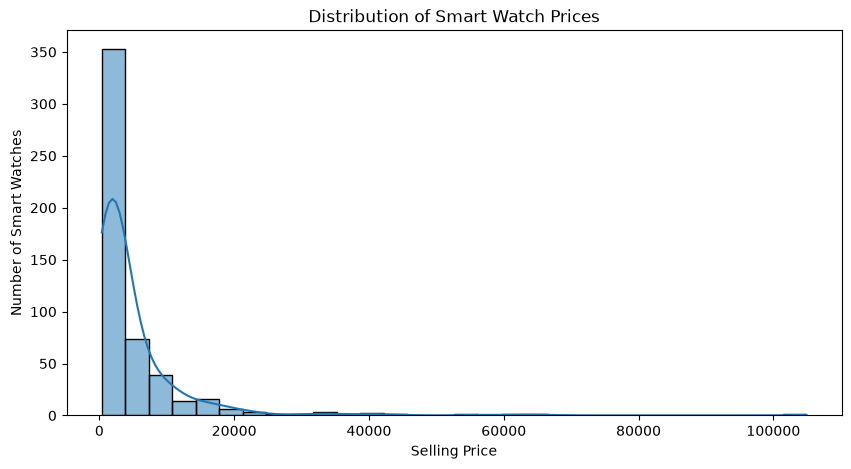

In [48]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Price",
    bins=30,
    kde=True
)

plt.title("Distribution of Smart Watch Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Smart Watches")
plt.show()

### 2. Top 10 Brands — Univariate Analysis

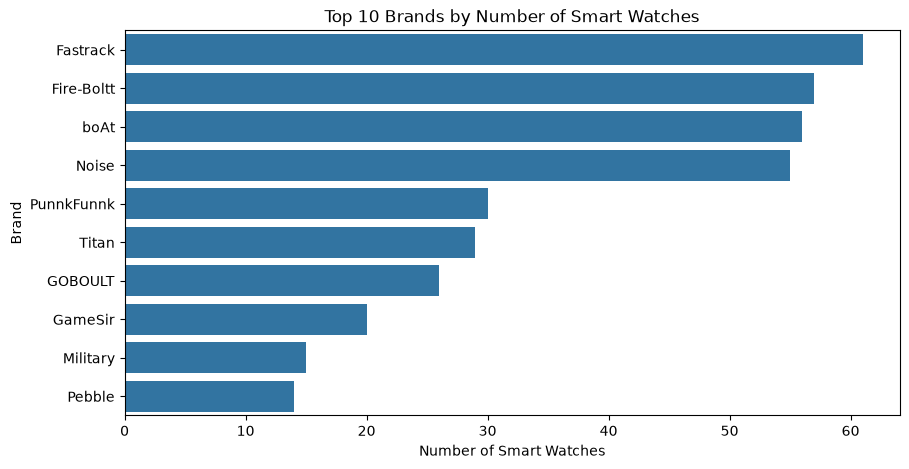

In [49]:
top_brands = df["Brand"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_brands.values,
    y=top_brands.index
)

plt.title("Top 10 Brands by Number of Smart Watches")
plt.xlabel("Number of Smart Watches")
plt.ylabel("Brand")
plt.show()

### 3. Display Size Distribution — Univariate Analysis

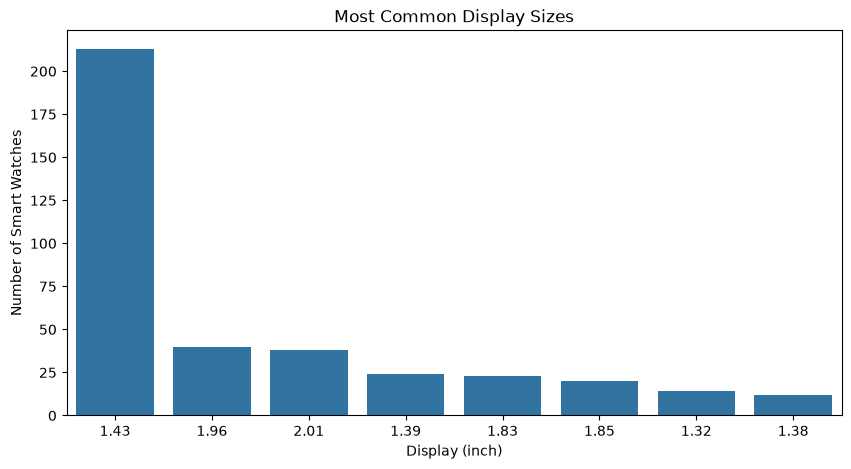

In [50]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Display",
    order=df["Display"].value_counts().head(8).index
)

plt.title("Most Common Display Sizes")
plt.xlabel("Display (inch)")
plt.ylabel("Number of Smart Watches")
plt.show()

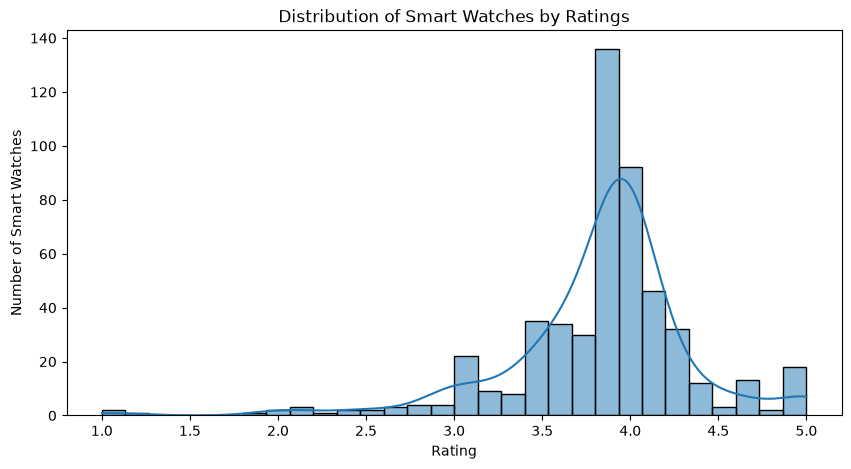

In [51]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Rating",
    bins=30,
    kde=True
)

plt.title("Distribution of Smart Watches by Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Smart Watches")
plt.show()

### 4. Brand Comparison — Bivariate Analysis

In [52]:
big_brands = df["Brand"].value_counts()[lambda s: s >= 5].index

brand_price = (
    df[df["Brand"].isin(big_brands)]
    .groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

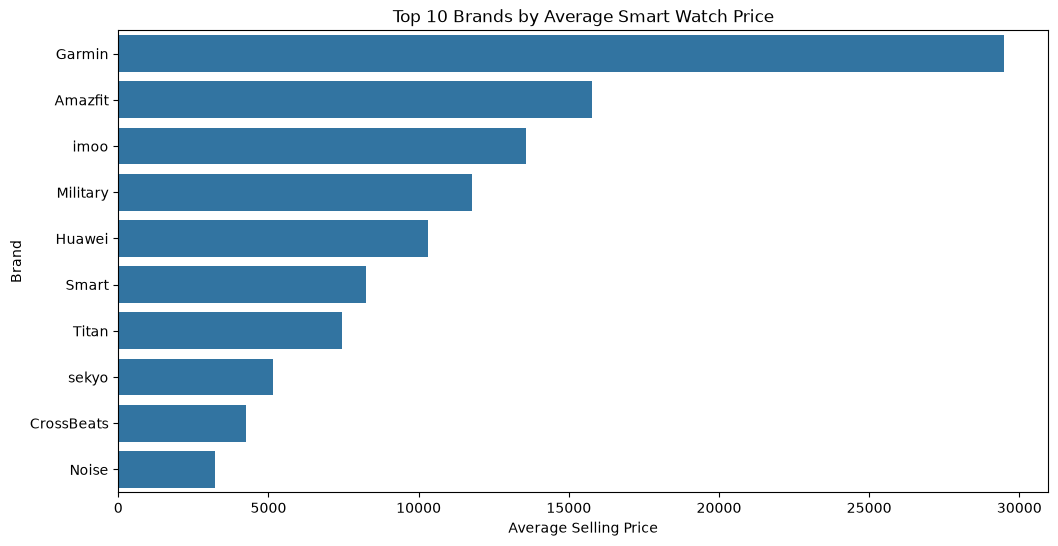

In [53]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=brand_price,
    x="Price",
    y="Brand"
)

plt.title("Top 10 Brands by Average Smart Watch Price")
plt.xlabel("Average Selling Price")
plt.ylabel("Brand")
plt.show()

### 5. Display Size Comparison — Bivariate Analysis

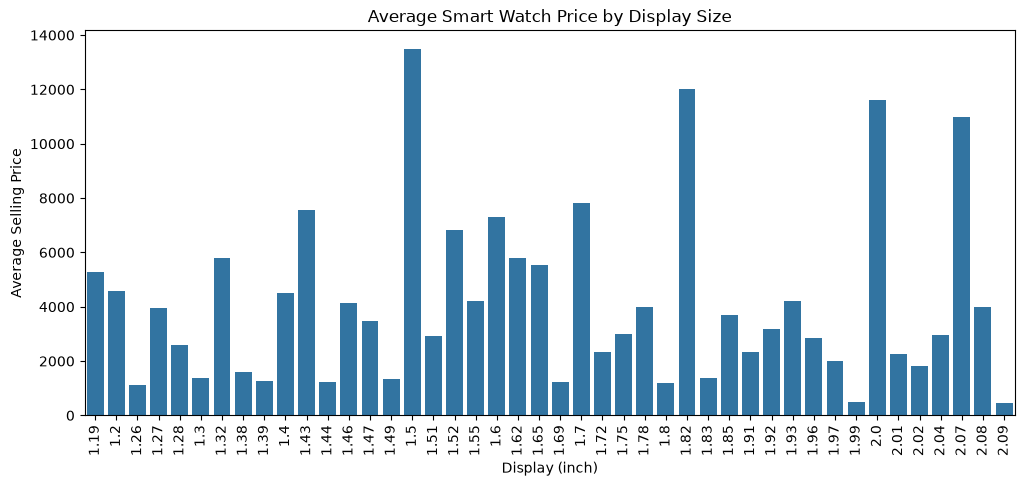

In [54]:
display_price = (
    df.groupby("Display")["Price"]
    .mean()
    .sort_index()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=display_price,
    x="Display",
    y="Price"
)

plt.title("Average Smart Watch Price by Display Size")
plt.xlabel("Display (inch)")
plt.ylabel("Average Selling Price")
plt.xticks(rotation=90)
plt.show()

### 6. Price vs Rating — Bivariate Analysis

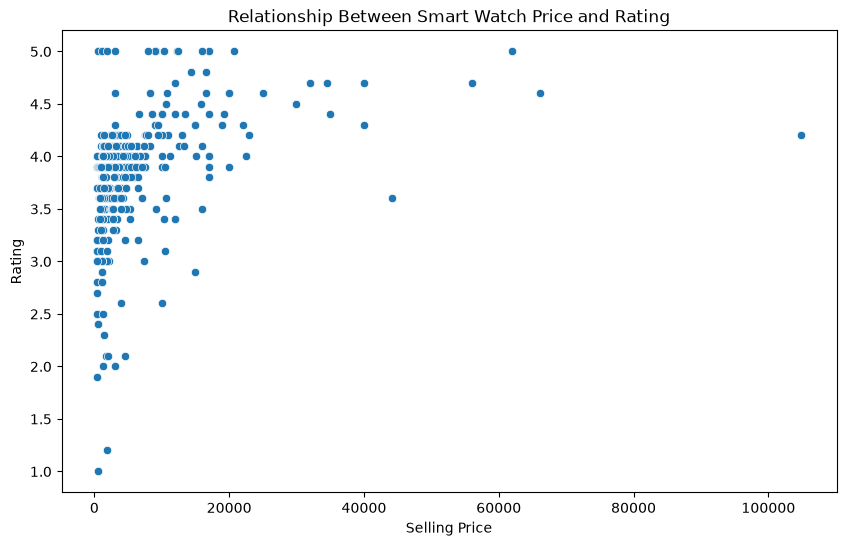

In [55]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Price",
    y="Rating"
)

plt.title("Relationship Between Smart Watch Price and Rating")
plt.xlabel("Selling Price")
plt.ylabel("Rating")
plt.show()

### 7. Correlation Heatmap — Multivariate Analysis

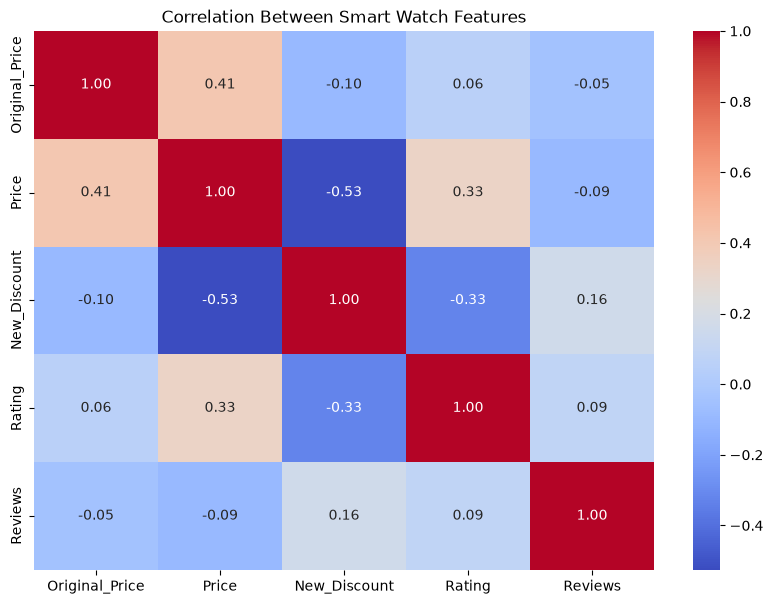

In [56]:
columns = [
    "Original_Price",
    "Price",
    "New_Discount",
    "Rating",
    "Reviews"
]

correlation = df[columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Smart Watch Features")
plt.show()

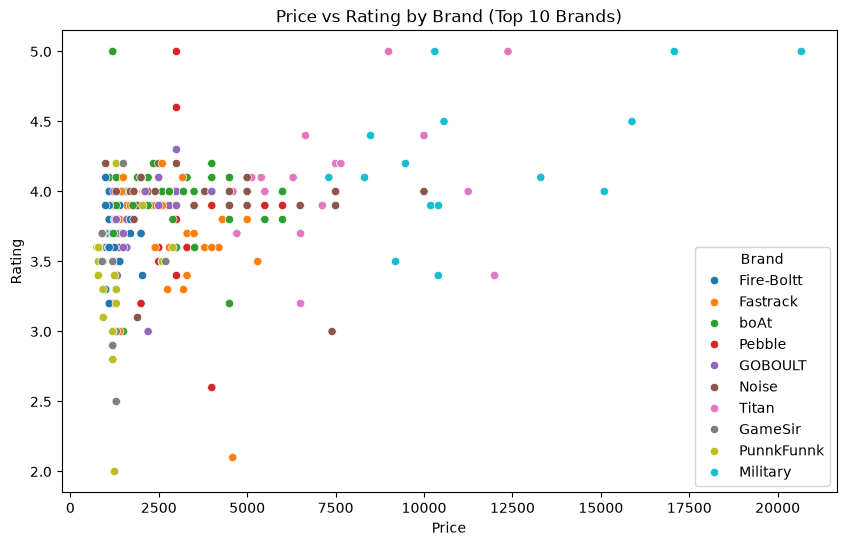

In [57]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x="Price",
                y="Rating",
                hue="Brand",
                data=df[df["Brand"].isin(top_brands.index)])

plt.title("Price vs Rating by Brand (Top 10 Brands)")
plt.show()

### 9. Premium Smart Watch Analysis

In [58]:
premium_watches = df[df["Price_Category"] == "Premium"].copy()

premium_brand = (
    premium_watches["Brand"]
    .value_counts()
    .head(10)
)

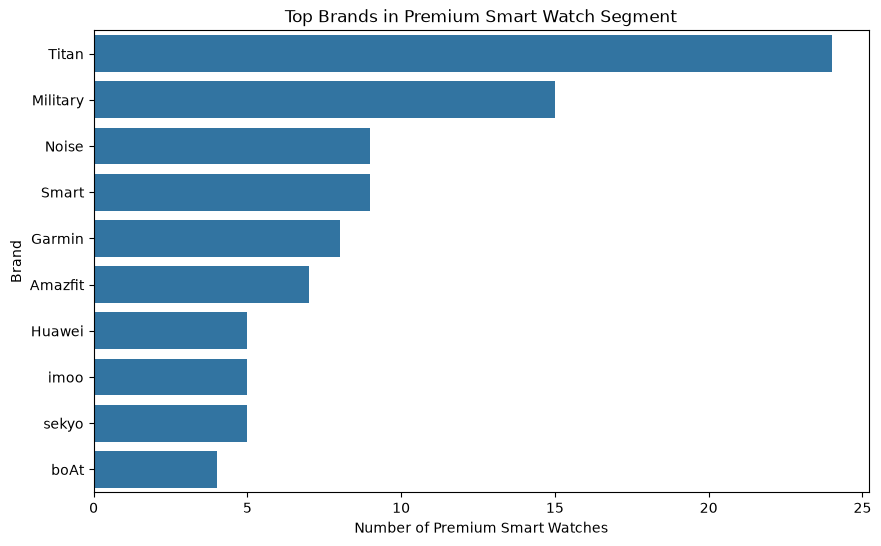

In [59]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=premium_brand.values,
    y=premium_brand.index
)

plt.title("Top Brands in Premium Smart Watch Segment")
plt.xlabel("Number of Premium Smart Watches")
plt.ylabel("Brand")
plt.show()

## Testing

### 1. IQR Method (Outlier Detection)

- The IQR (Interquartile Range) method finds outliers in numerical columns without assuming any particular distribution.
- IQR = Q3 − Q1. Any value below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR** is treated as an outlier.
- Columns checked: Price, Original_Price, Rating, Reviews, New_Discount.

        Column     Q1      Q3    IQR  Lower Bound  Upper Bound  Outliers  Outlier %
         Price 1249.0  4999.0 3750.0      -4376.0      10624.0        53      10.25
Original_Price 4999.0 11999.0 7000.0      -5501.0      22499.0        28       5.42
        Rating    3.6     4.0    0.4          3.0          4.6        50       9.67
       Reviews   22.0  1000.0  978.0      -1445.0       2467.0        85      16.44
  New_Discount   38.0    80.0   42.0        -25.0        143.0         0       0.00


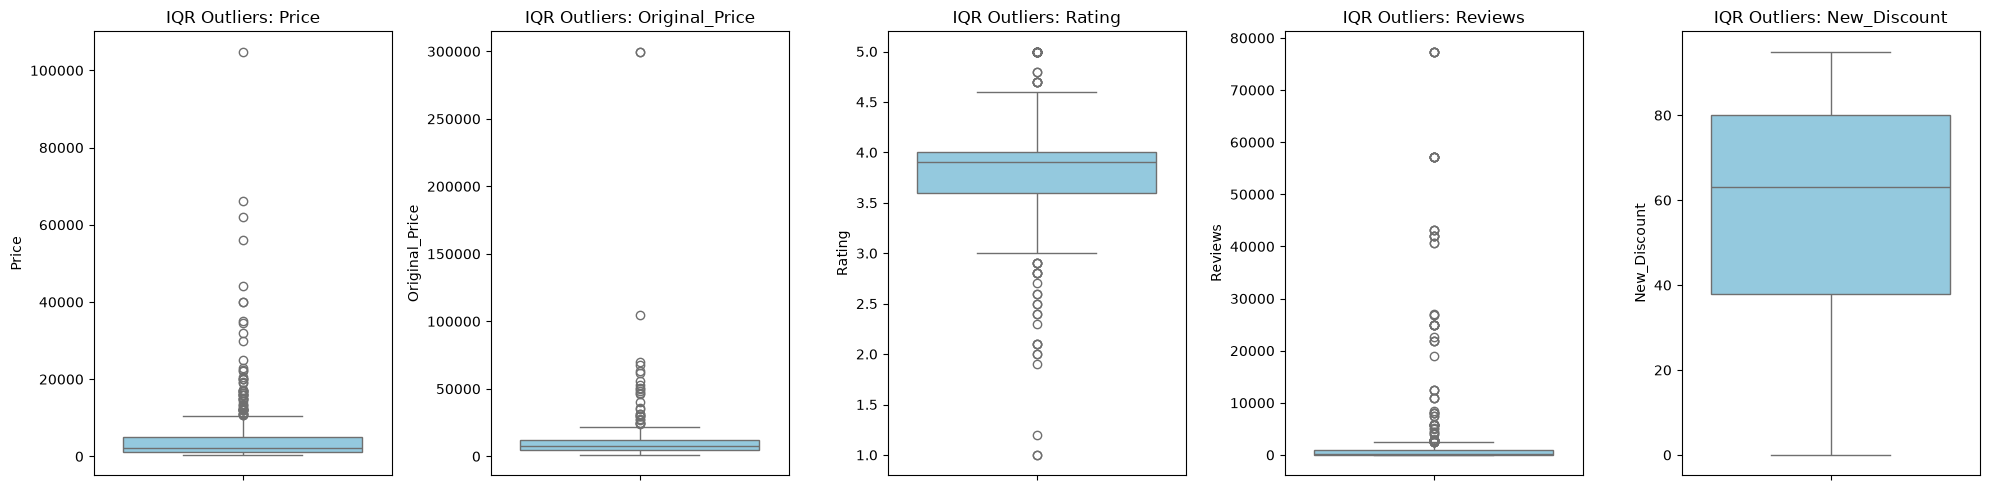

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ["Price", "Original_Price", "Rating", "Reviews", "New_Discount"]

iqr_summary = []
for col in num_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    iqr_summary.append([col, Q1, Q3, IQR, lower, upper, n_out, round(n_out / len(df) * 100, 2)])

iqr_table = pd.DataFrame(iqr_summary, columns=["Column", "Q1", "Q3", "IQR", "Lower Bound", "Upper Bound", "Outliers", "Outlier %"])
print(iqr_table.to_string(index=False))

# Box plots - dots outside the whiskers are the IQR outliers
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"IQR Outliers: {col}")
plt.tight_layout()
plt.show()

### 2. Z-Score Method (Outlier Detection)

- The Z-score tells how many standard deviations a value is away from the mean: **Z = (x − mean) / std**.
- Any value with |Z| > 3 is treated as an outlier.
- Columns checked: Price, Original_Price, Rating, Reviews, New_Discount.

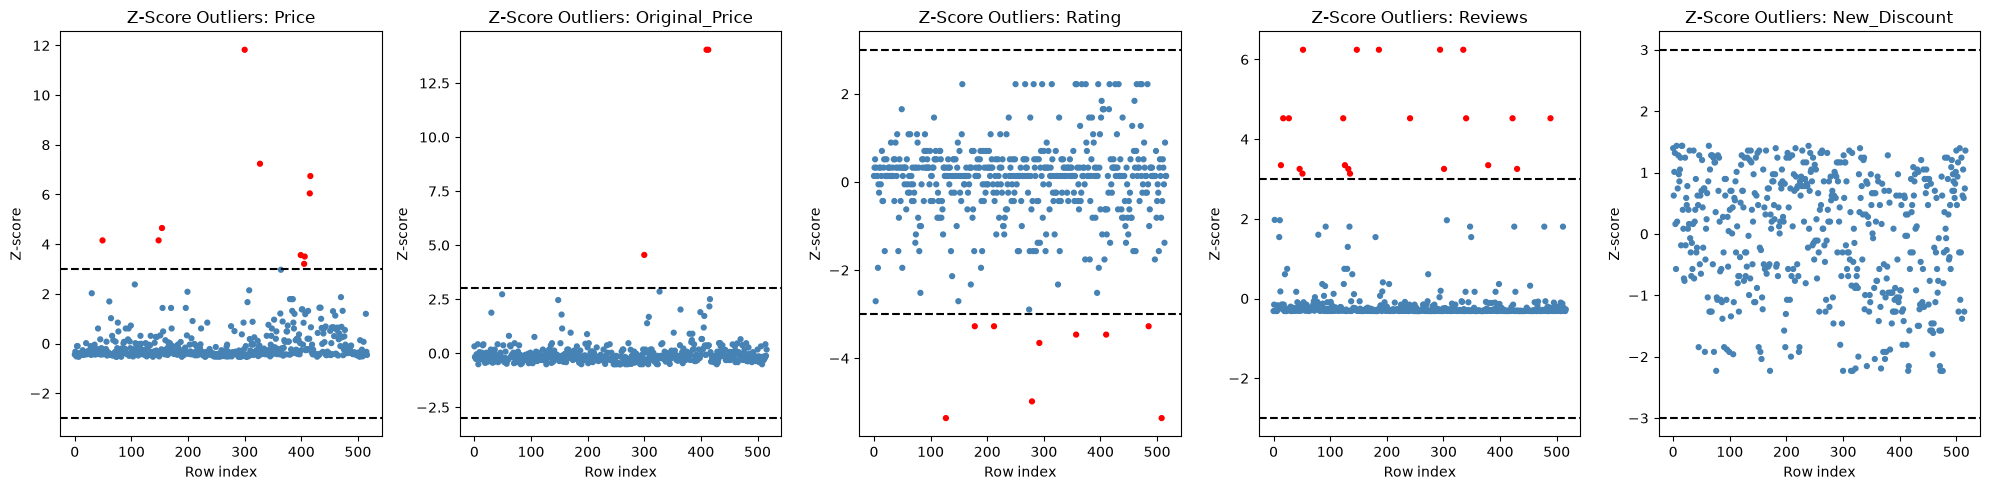

        Column     Mean      Std  Outliers (|Z|>3)  Outlier %
         Price  4868.36  8458.64                10       1.93
Original_Price 11467.64 20542.47                 3       0.58
        Rating     3.83     0.53                 9       1.74
       Reviews  3705.38 11804.84                21       4.06
  New_Discount    57.81    25.92                 0       0.00


In [62]:
z_threshold = 3

z_summary = []
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 5))
for ax, col in zip(axes, num_cols):
    z = (df[col] - df[col].mean()) / df[col].std()
    is_out = z.abs() > z_threshold
    z_summary.append([col, round(df[col].mean(), 2), round(df[col].std(), 2), is_out.sum(), round(is_out.sum() / len(df) * 100, 2)])

    # Z-score scatter - red points are outliers (beyond the dashed lines)
    ax.scatter(range(len(z)), z, c=is_out.map({True: "red", False: "steelblue"}), s=12)
    ax.axhline(z_threshold, color="black", linestyle="--")
    ax.axhline(-z_threshold, color="black", linestyle="--")
    ax.set_title(f"Z-Score Outliers: {col}")
    ax.set_xlabel("Row index")
    ax.set_ylabel("Z-score")
plt.tight_layout()
plt.show()

z_table = pd.DataFrame(z_summary, columns=["Column", "Mean", "Std", "Outliers (|Z|>3)", "Outlier %"])
print(z_table.to_string(index=False))

## Business questions

### Market Share: Which smart watch brand has the highest number of product listings on Amazon?

In [63]:
df['Brand'].value_counts().sort_values(ascending = False).head(1)

Brand
Fastrack    61
Name: count, dtype: int64

### Which brand has the highest average price

In [64]:
highest_avg_prices = df.groupby('Brand')['Price'].mean().sort_values(ascending = False).head(1)
print(highest_avg_prices)

Brand
Apple    58324.5
Name: Price, dtype: float64


### Pricing Strategy: What is the average, median, minimum, and maximum price of smart watches across the entire platform?

In [65]:
print(f"Minimum Price of smart watch : {df['Price'].min()}")
print(f"Maximum Price of smart watch : {df['Price'].max()}")
print(f"Average Price of smart watch : {round(df['Price'].mean())}")
print(f"Median Price of smart watch : {df['Price'].median()}")

Minimum Price of smart watch : 369
Maximum Price of smart watch : 104900
Average Price of smart watch : 4868
Median Price of smart watch : 2059.0


### Which display size is most common

In [66]:
common_display = df['Display'].value_counts().sort_values(ascending = False).head(1)
print(common_display)

Display
1.43    213
Name: count, dtype: int64


### How many smart watches support Bluetooth calling

In [67]:
common_calling = df['Calling'].value_counts()
calling = common_calling.idxmax()
count = common_calling.max()
print(calling, ':', count)

Yes : 367


### Are calling smart watches generally more expensive than non-calling smart watches?

In [68]:
avg_calling_prices = df.groupby('Calling')['Price'].mean()
if avg_calling_prices["Yes"] > avg_calling_prices["No"]:
    print('YES! Calling smart watches are more expensive than non-calling smart watches')
else:
    print("Non-calling smart watches are more expensive than calling smart watches")

Non-calling smart watches are more expensive than calling smart watches


### Do higher-priced smart watches receive better ratings?

In [69]:
priced_rating = df.groupby("Price_Category")['Rating'].mean()
print(priced_rating)
print(priced_rating.idxmax(), "smart watches receive the best rating")

Price_Category
Budget       3.666016
Mid Range    3.826667
Premium      4.160317
Name: Rating, dtype: float64
Premium smart watches receive the best rating


### Which brands offer the highest average discounts?

In [70]:
avg_discounts = df.groupby('Brand')['New_Discount'].mean()
print(avg_discounts.idxmax(), 'is offering the highest average discounts')

1.83" is offering the highest average discounts


### Which brands dominate the premium (>= ₹5,000) segment?

In [71]:
brand_segments = df.groupby('Price_Category')['Brand'].value_counts()
print(brand_segments["Premium"].idxmax(), "Brand dominates the premium segments")

Titan Brand dominates the premium segments


In [72]:
# Export the cleaned data to Excel
df.to_excel("Smartwatch_Cleaned_Data.xlsx", index=False)